# Sampling, the CLT in Practice, and the Bootstrap

**What you'll learn**

- How sampling distributions and standard errors behave on realistic, skewed
  business data (lognormal "revenue per user"), and why SE shrinks like $1/\sqrt{n}$
  while SD does not shrink at all.
- How fast the CLT actually kicks in for normal, uniform, lognormal, and
  heavy-tailed (Pareto) data — and where the "n = 30" folklore breaks.
- What CLT failure costs you in practice: real vs nominal t-interval coverage on
  skewed data, measured by simulation.
- The bootstrap end-to-end: mechanics, bootstrap SE, percentile and basic CIs for
  means, medians, quantiles, and ratio-of-means metrics that have no closed-form SE.
- Where the bootstrap fails — extreme quantiles (max, p99), tiny n, dependent
  data — and the block and cluster bootstrap fixes.

**Why it matters in interviews**

- "What's the difference between SD and SE?" and "why n = 30?" are classic
  screeners; senior candidates are expected to know when the folklore is wrong.
- "How would you get a confidence interval for the median / p90 latency / revenue
  per session?" is a staple of product-analytics interviews — the answer is a
  bootstrap, plus knowing its failure modes.
- Experimentation roles probe whether you know that sessions from the same user
  are dependent, and that naive SEs/bootstraps are anticonservative there.
- Coverage simulations ("how would you check your CI actually works?") separate
  candidates who *use* formulas from those who can *validate* them.

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
from scipy import signal
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 120)


def pct_ci(boot_stats, alpha=0.05):
    """Percentile bootstrap CI: central 1-alpha interval of the bootstrap stats."""
    return np.quantile(boot_stats, [alpha / 2, 1 - alpha / 2])


def basic_ci(theta_hat, boot_stats, alpha=0.05):
    """Basic (reverse-percentile) bootstrap CI: 2*theta_hat - flipped quantiles."""
    lo, hi = np.quantile(boot_stats, [alpha / 2, 1 - alpha / 2])
    return np.array([2 * theta_hat - hi, 2 * theta_hat - lo])


def covers(ci, truth):
    return ci[0] <= truth <= ci[1]

## 1. Sampling distributions and standard errors, hands-on

Our running population is **revenue per user**, modeled as
$\text{LogNormal}(\mu=3.0, \sigma=1.2)$. This is a deliberately realistic choice:
most users spend little, a few "whales" spend a lot, the mean is roughly twice the
median, and the population skewness is ~11. Almost every revenue, GMV, LTV, or
latency metric you will meet in industry looks like this — *not* like a normal
distribution.

Two quantities that interviewers love to see you keep apart:

- **SD** describes the spread of *individual observations*. It is a property of the
  population; collecting more data does not shrink it.
- **SE** describes the spread of an *estimator* (here, the sample mean) across
  repeated samples. For the mean, $SE = \sigma/\sqrt{n}$: it shrinks with
  $\sqrt{n}$, which is why halving a CI's width costs 4x the sample.

Population truth (analytic): mean = 41.26, sd = 74.05, median = 20.09, skewness = 11.2


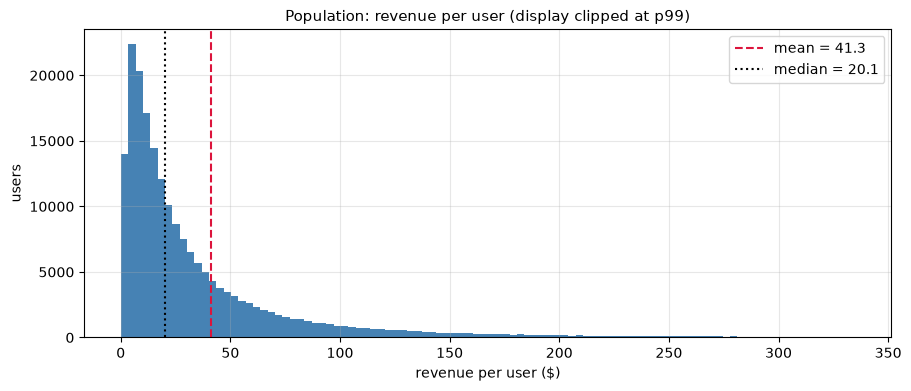

In [2]:
MU, SIGMA = 3.0, 1.2
true_mean = np.exp(MU + SIGMA**2 / 2)
true_sd = true_mean * np.sqrt(np.exp(SIGMA**2) - 1)
true_median = np.exp(MU)
true_skew = (np.exp(SIGMA**2) + 2) * np.sqrt(np.exp(SIGMA**2) - 1)

print(f"Population truth (analytic): mean = {true_mean:.2f}, sd = {true_sd:.2f}, "
      f"median = {true_median:.2f}, skewness = {true_skew:.1f}")

pop_preview = rng.lognormal(MU, SIGMA, 200_000)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(pop_preview[pop_preview < np.quantile(pop_preview, 0.99)], bins=100,
        color="steelblue", edgecolor="none")
ax.axvline(true_mean, color="crimson", ls="--", label=f"mean = {true_mean:.1f}")
ax.axvline(true_median, color="black", ls=":", label=f"median = {true_median:.1f}")
ax.set(title="Population: revenue per user (display clipped at p99)",
       xlabel="revenue per user ($)", ylabel="users")
ax.legend()
plt.show()

### One sample vs the sampling distribution

We now do what theory says but analysts rarely visualize: draw **10,000 independent
samples** of n = 200 users and look at the distribution of the *sample mean* across
samples. The data histogram stays wildly skewed; the histogram of means is far
narrower and much more symmetric — that narrowness *is* the standard error.

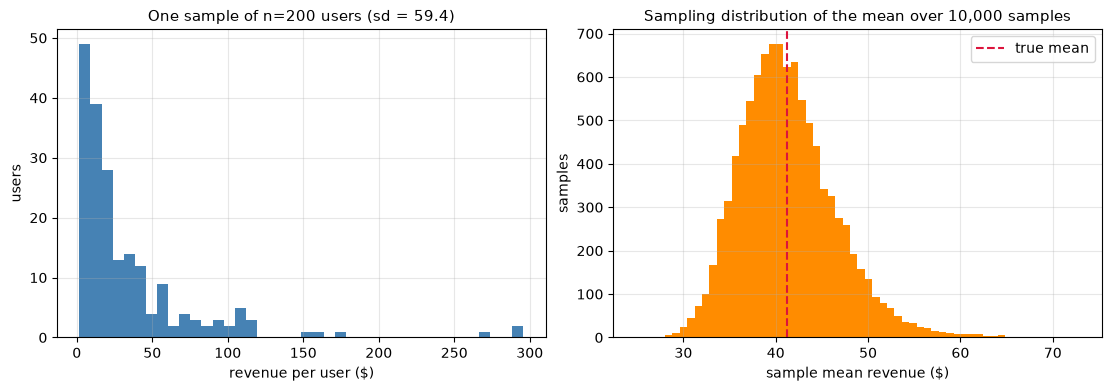

SD of individual revenues (one sample):     59.44
Empirical SE (sd of the 10,000 sample means):   5.21
Analytic SE  sigma/sqrt(n) = 74.05/sqrt(200) =   5.24


In [3]:
n_demo, R_demo = 200, 10_000
samples = rng.lognormal(MU, SIGMA, (R_demo, n_demo))
sample_means = samples.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
one_sample = samples[0]
axes[0].hist(one_sample[one_sample < np.quantile(one_sample, 0.99)], bins=40,
             color="steelblue")
axes[0].set(title=f"One sample of n={n_demo} users (sd = {one_sample.std(ddof=1):.1f})",
            xlabel="revenue per user ($)", ylabel="users")
axes[1].hist(sample_means, bins=60, color="darkorange")
axes[1].axvline(true_mean, color="crimson", ls="--", label="true mean")
axes[1].set(title=f"Sampling distribution of the mean over {R_demo:,} samples",
            xlabel="sample mean revenue ($)", ylabel="samples")
axes[1].legend()
plt.show()

print(f"SD of individual revenues (one sample):  {one_sample.std(ddof=1):8.2f}")
print(f"Empirical SE (sd of the {R_demo:,} sample means): {sample_means.std(ddof=1):6.2f}")
print(f"Analytic SE  sigma/sqrt(n) = {true_sd:.2f}/sqrt({n_demo}) = "
      f"{true_sd / np.sqrt(n_demo):6.2f}")

### SE shrinks like $1/\sqrt{n}$; SD does not shrink at all

The table and log-log plot below make the point empirically: the average
within-sample SD is flat in n, while the empirical SE tracks
$\sigma/\sqrt{n}$ with a log-log slope of −1/2.

   n  avg within-sample SD  empirical SE of mean  analytic SE sigma/sqrt(n)
  10                 53.28                 23.18                      23.42
  40                 62.44                 11.93                      11.71
 160                 69.00                  6.05                       5.85
 640                 71.38                  2.96                       2.93
2560                 73.30                  1.44                       1.46

log-log slope of SE vs n: -0.502  (theory: -0.5)


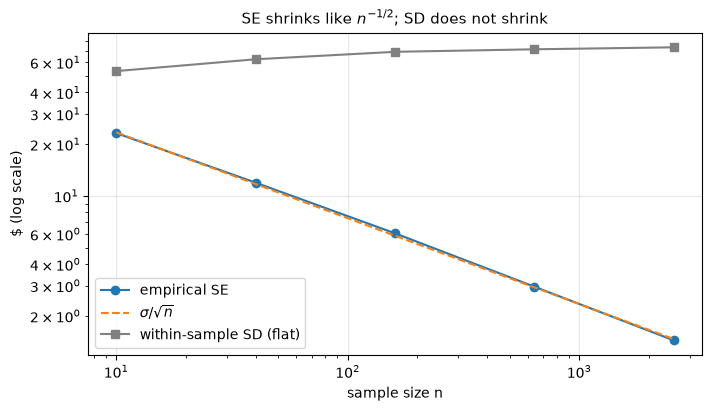

In [4]:
ns_se = np.array([10, 40, 160, 640, 2560])
rows = []
for n in ns_se:
    X = rng.lognormal(MU, SIGMA, (4000, n))
    rows.append({
        "n": n,
        "avg within-sample SD": X.std(axis=1, ddof=1).mean(),
        "empirical SE of mean": X.mean(axis=1).std(ddof=1),
        "analytic SE sigma/sqrt(n)": true_sd / np.sqrt(n),
    })
se_table = pd.DataFrame(rows)
print(se_table.round(2).to_string(index=False))

slope = np.polyfit(np.log(ns_se), np.log(se_table["empirical SE of mean"]), 1)[0]
print(f"\nlog-log slope of SE vs n: {slope:.3f}  (theory: -0.5)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(ns_se, se_table["empirical SE of mean"], "o-", label="empirical SE")
ax.loglog(ns_se, true_sd / np.sqrt(ns_se), "--", label=r"$\sigma/\sqrt{n}$")
ax.loglog(ns_se, se_table["avg within-sample SD"], "s-", color="gray",
          label="within-sample SD (flat)")
ax.set(title="SE shrinks like $n^{-1/2}$; SD does not shrink",
       xlabel="sample size n", ylabel="$ (log scale)")
ax.legend()
plt.show()

## 2. CLT convergence: how fast does the mean normalize?

The CLT is an asymptotic statement — it says nothing about *how fast* the sampling
distribution of the mean approaches normal. The rate is governed by skewness and
tail weight (Berry–Esseen: the error decays like $\mathbb{E}|X|^3 / (\sigma^3\sqrt{n})$,
so heavy third moments mean slow convergence).

We compare four populations at $n \in \{5, 30, 200, 1000\}$:

| population | shape | expectation |
|---|---|---|
| Normal(0,1) | symmetric, light tails | exact at every n |
| Uniform(0,1) | symmetric, bounded | essentially normal by n = 5 |
| LogNormal(3, 1.2) | skew ≈ 11 | slow — skew of the mean decays only as $11/\sqrt{n}$ |
| Pareto(α = 2.5) | finite variance, **infinite third moment** | very slow; sample skewness itself is unstable |

For each we standardize the sample mean with the *true* mean and SE and measure:
skewness of the sampling distribution, the Kolmogorov–Smirnov distance to N(0,1),
and the realized tail probabilities $P(Z > 1.96)$ and $P(Z < -1.96)$ (each
nominally 2.5% — these are exactly the error rates of one-sided z-tests).

In [5]:
pareto_a = 2.5
clt_pops = {
    "Normal(0,1)": (lambda size: rng.normal(0, 1, size), 0.0, 1.0),
    "Uniform(0,1)": (lambda size: rng.uniform(0, 1, size), 0.5, np.sqrt(1 / 12)),
    "LogNormal(3,1.2)": (lambda size: rng.lognormal(MU, SIGMA, size),
                         true_mean, true_sd),
    "Pareto(a=2.5)": (lambda size: 1 + rng.pareto(pareto_a, size),
                      pareto_a / (pareto_a - 1),
                      np.sqrt(pareto_a / ((pareto_a - 1) ** 2 * (pareto_a - 2)))),
}
ns_clt = [5, 30, 200, 1000]
R_CLT = 20_000

clt_rows, z_store = [], {}
for name, (sampler, pop_mean, pop_sd) in clt_pops.items():
    for n in ns_clt:
        means = sampler((R_CLT, n)).mean(axis=1)
        z = (means - pop_mean) / (pop_sd / np.sqrt(n))
        z_store[(name, n)] = z
        clt_rows.append({
            "population": name, "n": n,
            "skew of sampling dist": st.skew(z),
            "KS dist to N(0,1)": st.kstest(z, "norm").statistic,
            "P(Z>1.96)": (z > 1.96).mean(),
            "P(Z<-1.96)": (z < -1.96).mean(),
        })
clt_table = pd.DataFrame(clt_rows)
print(clt_table.round(3).to_string(index=False))

      population    n  skew of sampling dist  KS dist to N(0,1)  P(Z>1.96)  P(Z<-1.96)
     Normal(0,1)    5                 -0.024              0.005      0.025       0.026
     Normal(0,1)   30                 -0.011              0.004      0.026       0.025
     Normal(0,1)  200                 -0.041              0.006      0.023       0.027
     Normal(0,1) 1000                 -0.025              0.006      0.026       0.025
    Uniform(0,1)    5                 -0.011              0.008      0.021       0.023
    Uniform(0,1)   30                 -0.006              0.008      0.024       0.025
    Uniform(0,1)  200                  0.009              0.008      0.027       0.027
    Uniform(0,1) 1000                 -0.010              0.004      0.025       0.026
LogNormal(3,1.2)    5                  6.148              0.151      0.037       0.000
LogNormal(3,1.2)   30                  1.834              0.083      0.039       0.000
LogNormal(3,1.2)  200                  0.82

Read the lognormal rows: at the folklore threshold **n = 30 the sampling
distribution still has skew ≈ 1.8**, the upper-tail error runs ~3.9% against the
nominal 2.5%, and the lower tail is *empty* (0.000). The total two-sided error
looks deceptively fine — but it all sits on one side, so a one-sided test rejects
~60% too often in one direction and essentially never in the other. Even at
n = 1000 the lognormal mean keeps visible skew (theory: $11.1/\sqrt{1000}
\approx 0.35$). The Pareto rows are worse *and* erratic — note the skewness
estimate jumping to ~49 at n = 200: with an infinite third moment the statistic
itself refuses to settle. Meanwhile the uniform is indistinguishable from normal
at n = 5 — "n ≥ 30" is neither necessary nor sufficient. **The right question is
not "is n ≥ 30" but "how skewed / heavy-tailed is the underlying data relative to
my n".**

QQ plots make the same point visually — watch the upper-right corner peel off the
line for the skewed and heavy-tailed rows.

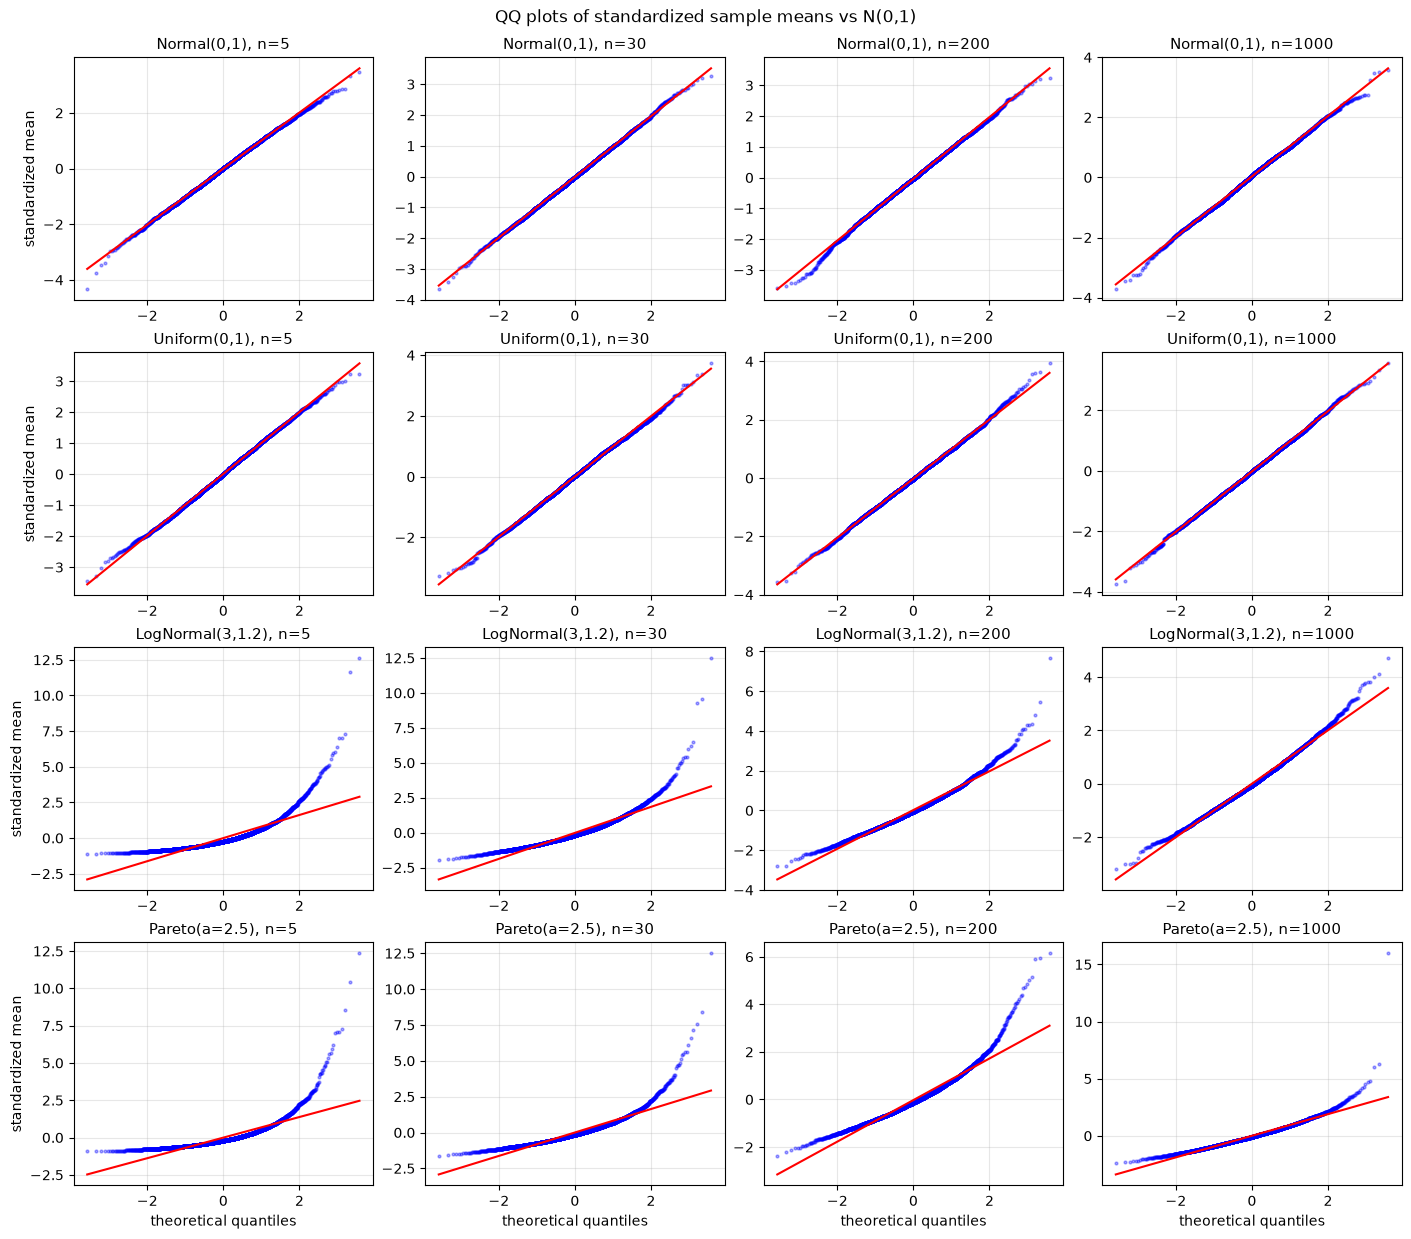

In [6]:
fig, axes = plt.subplots(4, 4, figsize=(14, 12))
for i, name in enumerate(clt_pops):
    for j, n in enumerate(ns_clt):
        ax = axes[i, j]
        st.probplot(z_store[(name, n)][:4000], dist="norm", plot=ax)
        ax.get_lines()[0].set(markersize=2, alpha=0.35)
        ax.set(title=f"{name}, n={n}",
               xlabel="theoretical quantiles" if i == 3 else "",
               ylabel="standardized mean" if j == 0 else "")
fig.suptitle("QQ plots of standardized sample means vs N(0,1)", y=1.02)
plt.show()

## 3. What it costs you: t-interval coverage on skewed data

CLT slowness is not academic — it directly corrupts the confidence intervals and
p-values you ship. Below we compute the classic 95% t-interval
$\bar{x} \pm t_{0.975, n-1}\, s/\sqrt{n}$ on lognormal revenue samples and measure,
over 10,000 replications per n, how often the interval actually contains the true
mean, and *which side* it misses on.

In [7]:
def t_coverage(ns, reps=10_000):
    rows = []
    for n in ns:
        X = rng.lognormal(MU, SIGMA, (reps, n))
        m, s = X.mean(axis=1), X.std(axis=1, ddof=1)
        half = st.t.ppf(0.975, n - 1) * s / np.sqrt(n)
        lo, hi = m - half, m + half
        rows.append({
            "n": n,
            "coverage": ((lo <= true_mean) & (true_mean <= hi)).mean(),
            "truth above CI": (true_mean > hi).mean(),
            "truth below CI": (true_mean < lo).mean(),
        })
    return pd.DataFrame(rows)

cov_t = t_coverage([10, 30, 100, 500, 2000])
print("95% t-interval, lognormal(3, 1.2) revenue  (MC error ~0.2pp):\n")
print(cov_t.round(3).to_string(index=False))

95% t-interval, lognormal(3, 1.2) revenue  (MC error ~0.2pp):

   n  coverage  truth above CI  truth below CI
  10     0.797           0.202           0.001
  30     0.845           0.154           0.001
 100     0.893           0.104           0.003
 500     0.934           0.060           0.007
2000     0.946           0.044           0.010


Three things a senior candidate should say about this table:

1. **Under-coverage, not over-coverage.** At n = 30 the "95%" interval covers only
   ~84% of the time, and even n = 500 has not fully recovered (~93%). Your stated
   false positive rate is understated.
2. **The misses are asymmetric.** Almost all failures are "truth above CI": a
   typical sample misses the whales, so both $\bar{x}$ and $s$ come out small and
   the whole interval sits too low. The errors are correlated — that is exactly
   what breaks the t-statistic's symmetry.
3. **In A/B testing you compare two means**, which cancels some skew (the
   difference of two right-skewed means is more symmetric), and per-arm n is
   usually large — that is why t-tests still mostly work in experimentation. The
   danger zone is small-n slices: per-country breakdowns, enterprise deals, rare
   segments. See `../02_ab_testing/02_power_mde_sample_size.ipynb` for the
   simulation approach to sizing such tests.

## 4. The bootstrap: mechanics, SE, percentile and basic CIs

The bootstrap replaces "imagine drawing repeated samples from the population" with
"actually draw repeated samples from the *empirical distribution*" — i.e. resample
your n observations **with replacement**, n at a time, and recompute the statistic
each time. The spread of those bootstrap statistics estimates the sampling
variability of your estimator. The plug-in principle is the whole trick: the
empirical CDF stands in for the unknown population CDF.

Why it earns its keep: it gives you SEs and CIs for statistics with no usable
formula — medians, p90s, trimmed means, ratios of means — with the *same* code.

Two classic nonparametric intervals from the bootstrap draws $\hat\theta^*_1,
\dots, \hat\theta^*_B$:

- **Percentile CI**: $[q^*_{\alpha/2},\; q^*_{1-\alpha/2}]$ — just the central
  quantiles of the bootstrap distribution.
- **Basic (reverse-percentile) CI**: $[2\hat\theta - q^*_{1-\alpha/2},\;
  2\hat\theta - q^*_{\alpha/2}]$ — approximates the distribution of the *error*
  $\hat\theta - \theta$ by the bootstrap error $\hat\theta^* - \hat\theta$, then
  flips it around the estimate.

They agree when the bootstrap distribution is symmetric and differ when it is
skewed or biased. Neither dominates; BCa (bias-corrected accelerated, in
`scipy.stats.bootstrap`) is the usual library default and is second-order accurate.

One rule that must become reflex: **resample the unit that was independently
sampled, and re-run the entire computation inside each resample.** For a ratio
metric like revenue per session computed over users, that means resampling *user
rows* (revenue and sessions together) and recomputing sum/sum each time.

In [8]:
# One realistic cross-section of users: sessions and revenue per user.
n_users = 500
sessions = 1 + rng.poisson(3.0, n_users)                       # sessions per user
spend_ps = np.exp(1.8 - 0.12 * sessions + rng.normal(0, 0.8, n_users))
revenue = sessions * spend_ps                                  # revenue per user

est = {
    "mean revenue/user": revenue.mean(),
    "median revenue/user": np.median(revenue),
    "p90 revenue/user": np.quantile(revenue, 0.9),
    "revenue per session (ratio of means)": revenue.sum() / sessions.sum(),
}

B = 4000
idx = rng.integers(0, n_users, (B, n_users))     # one index matrix, reused jointly
rev_b, ses_b = revenue[idx], sessions[idx]
boot = {
    "mean revenue/user": rev_b.mean(axis=1),
    "median revenue/user": np.median(rev_b, axis=1),
    "p90 revenue/user": np.quantile(rev_b, 0.9, axis=1),
    "revenue per session (ratio of means)": rev_b.sum(axis=1) / ses_b.sum(axis=1),
}

rows = []
for name, stats_ in boot.items():
    lo_p, hi_p = pct_ci(stats_)
    lo_b, hi_b = basic_ci(est[name], stats_)
    rows.append({
        "statistic": name, "estimate": est[name], "boot SE": stats_.std(ddof=1),
        "95% percentile CI": f"[{lo_p:.2f}, {hi_p:.2f}]",
        "95% basic CI": f"[{lo_b:.2f}, {hi_b:.2f}]",
    })
boot_table = pd.DataFrame(rows)
print(boot_table.round(2).to_string(index=False))
print(f"\nAnalytic SE for the mean, s/sqrt(n): {revenue.std(ddof=1)/np.sqrt(n_users):.2f} "
      "(matches the bootstrap SE — for the mean the bootstrap is just a simulation "
      "of the formula)")

                           statistic  estimate  boot SE 95% percentile CI   95% basic CI
                   mean revenue/user     20.32     0.84    [18.73, 22.04] [18.60, 21.91]
                 median revenue/user     14.65     0.50    [13.69, 15.63] [13.67, 15.61]
                    p90 revenue/user     40.71     2.21    [36.42, 44.71] [36.71, 45.01]
revenue per session (ratio of means)      5.05     0.20      [4.66, 5.46]   [4.64, 5.44]

Analytic SE for the mean, s/sqrt(n): 0.83 (matches the bootstrap SE — for the mean the bootstrap is just a simulation of the formula)


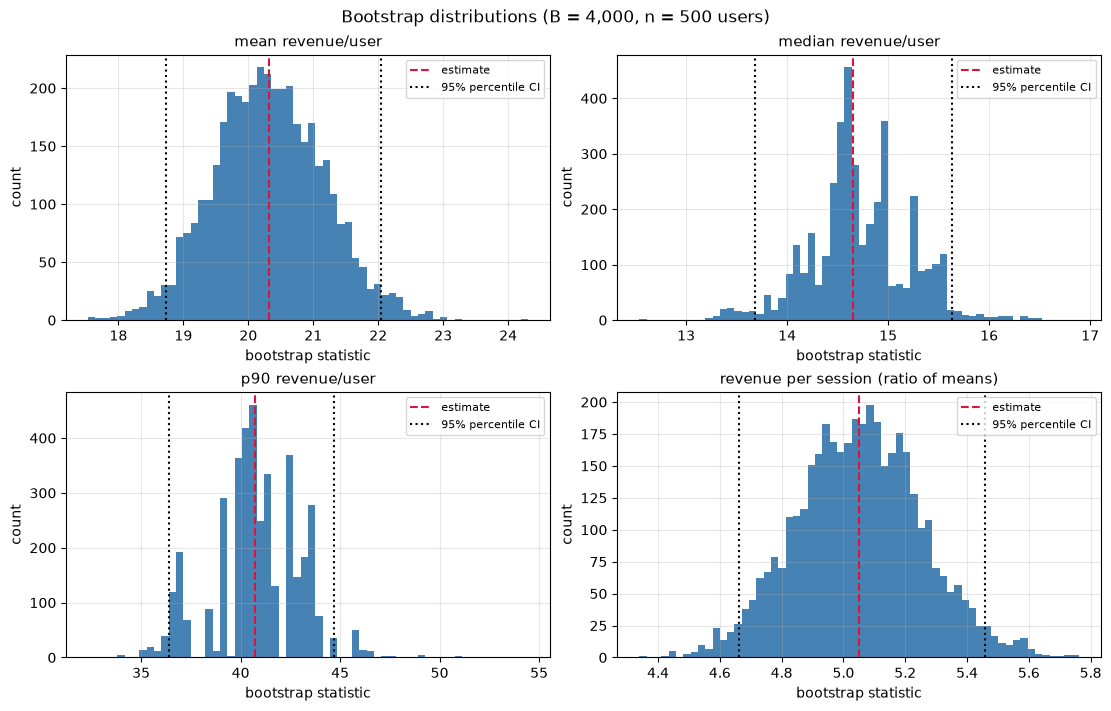

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, stats_) in zip(axes.ravel(), boot.items()):
    ax.hist(stats_, bins=60, color="steelblue")
    ax.axvline(est[name], color="crimson", ls="--", label="estimate")
    lo_p, hi_p = pct_ci(stats_)
    ax.axvline(lo_p, color="black", ls=":")
    ax.axvline(hi_p, color="black", ls=":", label="95% percentile CI")
    ax.set(title=name, xlabel="bootstrap statistic", ylabel="count")
    ax.legend(fontsize=8)
fig.suptitle(f"Bootstrap distributions (B = {B:,}, n = {n_users} users)")
plt.show()

Note the shapes: the mean's bootstrap distribution is near-symmetric, while the
median's is lumpy (it can only take values at observed data points — a preview of
why quantile bootstraps get fragile) and p90's is right-skewed. The ratio metric
behaves well here because n is decent; the delta-method analytic SE for ratios,
and what happens when the denominator gets noisy, is the subject of
`../02_ab_testing/05_ratio_metrics_delta_method.ipynb`.

For production use you rarely hand-roll this loop — `scipy.stats.bootstrap` gives
the same machinery plus the BCa correction:

In [10]:
res = st.bootstrap((revenue,), np.mean, n_resamples=4000, method="BCa",
                   confidence_level=0.95, random_state=np.random.default_rng(7))
print(f"scipy BCa 95% CI for the mean: [{res.confidence_interval.low:.2f}, "
      f"{res.confidence_interval.high:.2f}]  (SE {res.standard_error:.2f})")

scipy BCa 95% CI for the mean: [18.82, 22.07]  (SE 0.83)


## 5. Coverage check: bootstrap vs analytic CIs against ground truth

A CI method is only as good as its *realized* coverage, and we have ground truth,
so we can measure it. For 1,500 fresh lognormal samples of n = 50 we build five
intervals per sample — t, percentile, and basic for the **mean**; percentile and
basic for the **median** — and count how often each contains the truth.

In [11]:
SIMS, B_cov, n_cov = 1500, 1000, 50
tcrit = st.t.ppf(0.975, n_cov - 1)
hits = np.zeros((SIMS, 5), dtype=bool)

for s_i in range(SIMS):
    x = rng.lognormal(MU, SIGMA, n_cov)
    xb = x[rng.integers(0, n_cov, (B_cov, n_cov))]
    bmean, bmed = xb.mean(axis=1), np.median(xb, axis=1)
    m, half = x.mean(), tcrit * x.std(ddof=1) / np.sqrt(n_cov)
    hits[s_i] = [
        covers((m - half, m + half), true_mean),
        covers(pct_ci(bmean), true_mean),
        covers(basic_ci(m, bmean), true_mean),
        covers(pct_ci(bmed), true_median),
        covers(basic_ci(np.median(x), bmed), true_median),
    ]

cov5 = pd.DataFrame({
    "interval": ["mean: t", "mean: percentile boot", "mean: basic boot",
                 "median: percentile boot", "median: basic boot"],
    "coverage": hits.mean(axis=0),
})
print(f"Realized coverage of nominal 95% CIs, lognormal, n = {n_cov} "
      f"({SIMS} sims, MC error ~0.6pp):\n")
print(cov5.round(3).to_string(index=False))

Realized coverage of nominal 95% CIs, lognormal, n = 50 (1500 sims, MC error ~0.6pp):

               interval  coverage
                mean: t     0.871
  mean: percentile boot     0.872
       mean: basic boot     0.838
median: percentile boot     0.937
     median: basic boot     0.838


The verdict at this n and this much skew:

- **The bootstrap is not a magic fix for the mean.** The t and percentile
  intervals under-cover by the same ~8 points, and the basic interval is a bit
  worse still — the bootstrap inherits the exact problem the t-interval has (a
  typical sample under-represents the right tail, and resampling a whale-free
  sample cannot invent whales). Bootstrap ≠ more data.
- **For the median, the percentile interval is close to nominal** — the median
  doesn't depend on the tail, so its sampling distribution and its bootstrap both
  behave. This is the honest pitch for the bootstrap: not "better CIs for the
  mean", but "*valid* CIs for statistics that have no formula".
- **The basic interval visibly fails for the median.** The median's bootstrap
  distribution is discrete (it lives on observed order statistics), and the basic
  interval's reflection step amplifies that lumpiness. For quantile-like
  statistics prefer percentile or BCa over basic.

## 6. When the bootstrap fails

Three failure modes you should be able to demonstrate on a whiteboard.

### 6.1 Extreme order statistics: the max (and p99 at moderate n)

The bootstrap requires the statistic to depend *smoothly* on the empirical
distribution. The sample maximum does not. In any resample of size n, the
probability that the sample's largest point appears at least once is
$1 - (1 - 1/n)^n \to 1 - 1/e \approx 63\%$ — so the "bootstrap distribution of the
max" is mostly a point mass at the observed max and can never exceed it.

sample max = 0.9634   (true theta = 1)
share of bootstrap resamples whose max == sample max: 0.635   (theory 1-(1-1/n)^n = 0.636)


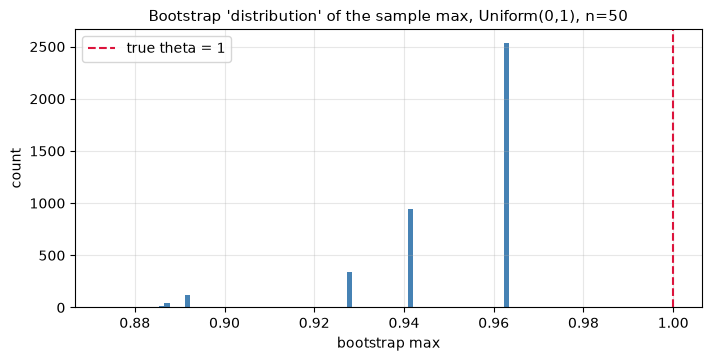


Coverage of nominal 95% percentile CI for theta over 2000 sims: 0.000


In [12]:
n_max = 50
x_unif = rng.uniform(0, 1, n_max)          # true upper bound theta = 1
bmax = x_unif[rng.integers(0, n_max, (4000, n_max))].max(axis=1)

print(f"sample max = {x_unif.max():.4f}   (true theta = 1)")
print(f"share of bootstrap resamples whose max == sample max: "
      f"{(bmax == x_unif.max()).mean():.3f}   "
      f"(theory 1-(1-1/n)^n = {1 - (1 - 1/n_max)**n_max:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(bmax, bins=80, color="steelblue")
ax.axvline(1.0, color="crimson", ls="--", label="true theta = 1")
ax.set(title="Bootstrap 'distribution' of the sample max, Uniform(0,1), n=50",
       xlabel="bootstrap max", ylabel="count")
ax.legend()
plt.show()

# Coverage of the 95% percentile CI for theta over repeated experiments:
cover_max = 0
SIMS_max = 2000
for _ in range(SIMS_max):
    x = rng.uniform(0, 1, n_max)
    bm = x[rng.integers(0, n_max, (1000, n_max))].max(axis=1)
    cover_max += covers(pct_ci(bm), 1.0)
print(f"\nCoverage of nominal 95% percentile CI for theta over {SIMS_max} sims: "
      f"{cover_max / SIMS_max:.3f}")

**Coverage is exactly zero.** The bootstrap CI's upper end can never reach beyond
the sample max, which is *always* below θ. This is not a small-sample blemish —
the bootstrap is inconsistent for extremes at any n. (Proper tools: parametric
models for the boundary, or extreme value theory — the same toolbox behind VaR-style
tail risk in `../09_finance_and_operations/02_returns_risk.ipynb`.)

The p99 is a softer version of the same disease: at n = 100 it sits on the one or
two largest points, so the bootstrap distribution is a few spikes and coverage
degrades; by n = 1000 there is real data in the tail and things mostly recover.

In [13]:
true_p99 = np.exp(MU + SIGMA * st.norm.ppf(0.99))

def p99_coverage(n, sims, B=1000):
    hit = 0
    for _ in range(sims):
        x = rng.lognormal(MU, SIGMA, n)
        bq = np.quantile(x[rng.integers(0, n, (B, n))], 0.99, axis=1)
        hit += covers(pct_ci(bq), true_p99)
    return hit / sims

print(f"true p99 of revenue = {true_p99:.1f}")
for n, sims in [(100, 1000), (1000, 600)]:
    print(f"n = {n:5d}: percentile-CI coverage for p99 = {p99_coverage(n, sims):.3f}")

true p99 of revenue = 327.5


n =   100: percentile-CI coverage for p99 = 0.636


n =  1000: percentile-CI coverage for p99 = 0.915


Rule of thumb: to bootstrap quantile q you want a comfortable number of
observations *beyond* q — think $n(1-q) \gtrsim 20{-}50$, i.e. p99 wants n in the
thousands. For medians and p90s at ordinary product-analytics n, you're fine.

### 6.2 Tiny n

The bootstrap is itself an asymptotic method: it approximates the sampling
distribution by resampling from n atoms. With n = 8 there is almost no information
about the tail of a skewed distribution, and the percentile interval is typically
*worse* than the t-interval because it is built from a handful of distinct values.

In [14]:
n_tiny, SIMS_tiny, B_tiny = 8, 3000, 2000
tcrit8 = st.t.ppf(0.975, n_tiny - 1)
hit_t = hit_pct = 0
for _ in range(SIMS_tiny):
    x = rng.lognormal(MU, SIGMA, n_tiny)
    m, half = x.mean(), tcrit8 * x.std(ddof=1) / np.sqrt(n_tiny)
    hit_t += covers((m - half, m + half), true_mean)
    bm = x[rng.integers(0, n_tiny, (B_tiny, n_tiny))].mean(axis=1)
    hit_pct += covers(pct_ci(bm), true_mean)

print(f"n = {n_tiny}, lognormal mean, nominal 95% ({SIMS_tiny} sims):")
print(f"  t-interval coverage:          {hit_t / SIMS_tiny:.3f}")
print(f"  percentile bootstrap coverage: {hit_pct / SIMS_tiny:.3f}")

n = 8, lognormal mean, nominal 95% (3000 sims):
  t-interval coverage:          0.782
  percentile bootstrap coverage: 0.740


Both are bad; the bootstrap is *worse*. "The bootstrap doesn't assume normality"
is true, but it assumes the empirical CDF resembles the population — at n = 8 on
skewed data it does not. Nothing rescues n = 8 except more data, a defensible
parametric model, or changing the estimand.

### 6.3 Dependent data: the iid bootstrap ignores autocorrelation

Resampling individual observations destroys their ordering, which silently asserts
independence. For a positively autocorrelated series — a daily KPI, say — the
variance of the mean is inflated by the autocorrelation
($\mathrm{Var}(\bar{x}) \approx \frac{\sigma_x^2}{n}\cdot\frac{1+\phi}{1-\phi}$ for
AR(1)), and the iid bootstrap misses that entirely.

The **moving block bootstrap** is the standard fix: resample contiguous blocks of
length b (long enough to contain the dependence) and glue them together, so
short-range correlation survives inside blocks. Block length trades off dependence
capture (long blocks) vs number of distinct blocks (short blocks); $b \sim n^{1/3}$
is the usual starting point.

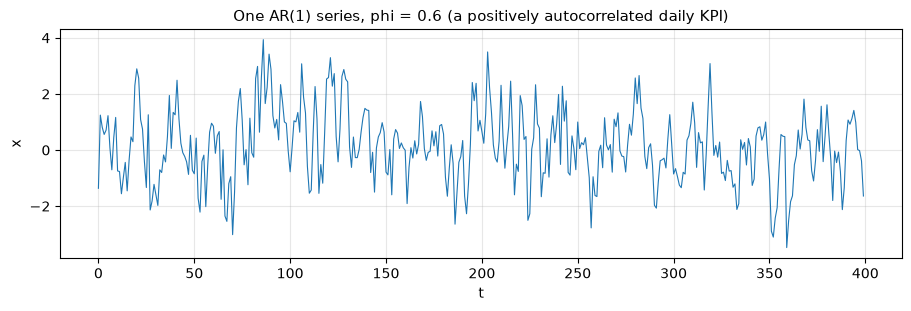

True SE of the mean (MC over 4000 series): 0.1259 (analytic 0.1250)
iid bootstrap SE   (avg over 200 series): 0.0617  -> underestimates truth by factor 2.04x
block bootstrap SE (b=20, avg):             0.1141  -> ratio to truth 0.91


In [15]:
phi, n_ts = 0.6, 400
R_true = 4000
eps = rng.normal(0, 1, (R_true, n_ts + 100))
series_all = signal.lfilter([1.0], [1.0, -phi], eps, axis=1)[:, 100:]  # AR(1), burn-in

sd_x = 1 / np.sqrt(1 - phi**2)
se_true_analytic = sd_x * np.sqrt((1 + phi) / (1 - phi) / n_ts)
se_true_mc = series_all.mean(axis=1).std(ddof=1)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(series_all[0], lw=0.8)
ax.set(title=f"One AR(1) series, phi = {phi} (a positively autocorrelated daily KPI)",
       xlabel="t", ylabel="x")
plt.show()

b_len = 20
k_blocks = n_ts // b_len
B_ts, n_series = 400, 200
se_iid, se_blk = np.empty(n_series), np.empty(n_series)
for i in range(n_series):
    x = series_all[i]
    se_iid[i] = x[rng.integers(0, n_ts, (B_ts, n_ts))].mean(axis=1).std(ddof=1)
    starts = rng.integers(0, n_ts - b_len + 1, (B_ts, k_blocks))
    blk_idx = (starts[:, :, None] + np.arange(b_len)).reshape(B_ts, -1)
    se_blk[i] = x[blk_idx].mean(axis=1).std(ddof=1)

print(f"True SE of the mean (MC over {R_true} series): {se_true_mc:.4f} "
      f"(analytic {se_true_analytic:.4f})")
print(f"iid bootstrap SE   (avg over {n_series} series): {se_iid.mean():.4f}  "
      f"-> underestimates truth by factor {se_true_mc / se_iid.mean():.2f}x")
print(f"block bootstrap SE (b={b_len}, avg):             {se_blk.mean():.4f}  "
      f"-> ratio to truth {se_blk.mean() / se_true_mc:.2f}")

The iid bootstrap SE is off by a factor of ~2 — i.e. your CI is half as wide as it
should be and your "significant" KPI shifts are routinely noise. The block
bootstrap recovers most of the truth (it still slightly underestimates because
correlation is broken at block boundaries; longer blocks reduce that bias at the
cost of noisier SEs — Exercise 3 maps this trade-off). Autocorrelation diagnostics
and time-series-aware inference are developed properly in
`../05_time_series/01_ts_foundations.ipynb`.

## 7. Cluster bootstrap preview: users inside session-level metrics

The dependence problem has a second, even more common disguise: **clustered
data**. If you randomize/sample *users* but analyze *sessions*, sessions from the
same user share that user's behavior and are correlated. Treating sessions as iid —
in a formula or in a bootstrap — understates the SE by roughly the design effect
$\sqrt{1 + (\bar{m} - 1)\rho}$ (cluster size $\bar m$, intra-class correlation ρ).

The fix is the **cluster bootstrap: resample users (with all their sessions), not
sessions.** Below: 500 users, ~5 sessions each, session-value ICC ≈ 0.31.

In [16]:
U, sess_rate = 500, 4.0
sig_u, sig_e, base = 2.0, 3.0, 10.0     # user effect sd, session noise sd
icc = sig_u**2 / (sig_u**2 + sig_e**2)

def sim_sessions():
    m = 1 + rng.poisson(sess_rate, U)              # sessions per user
    a = rng.normal(0, sig_u, U)                    # user effect
    y = base + np.repeat(a, m) + rng.normal(0, sig_e, m.sum())
    return y, m

# Ground truth: SD of the metric (mean session value) across 3000 fresh datasets
truth_metrics = np.array([sim_sessions()[0].mean() for _ in range(3000)])
se_true_cl = truth_metrics.std(ddof=1)

# Compare naive session-level vs cluster (user-level) bootstrap SE on 200 datasets
B_cl, n_data = 400, 200
se_naive, se_clust = np.empty(n_data), np.empty(n_data)
for i in range(n_data):
    y, m = sim_sessions()
    N = y.size
    se_naive[i] = y[rng.integers(0, N, (B_cl, N))].mean(axis=1).std(ddof=1)
    user_sum = np.bincount(np.repeat(np.arange(U), m), weights=y, minlength=U)
    user_cnt = m.astype(float)
    uidx = rng.integers(0, U, (B_cl, U))
    se_clust[i] = (user_sum[uidx].sum(axis=1) /
                   user_cnt[uidx].sum(axis=1)).std(ddof=1)

deff = 1 + (1 + sess_rate - 1) * icc
print(f"ICC = {icc:.3f}, avg cluster size = {1 + sess_rate:.0f} "
      f"-> design effect ~ {deff:.2f}, SE inflation ~ {np.sqrt(deff):.2f}x")
print(f"True SE of mean session value:      {se_true_cl:.4f}")
print(f"Naive session-bootstrap SE (avg):   {se_naive.mean():.4f}  "
      f"({se_naive.mean() / se_true_cl:.2f}x truth)")
print(f"Cluster (user) bootstrap SE (avg):  {se_clust.mean():.4f}  "
      f"({se_clust.mean() / se_true_cl:.2f}x truth)")

ICC = 0.308, avg cluster size = 5 -> design effect ~ 2.23, SE inflation ~ 1.49x
True SE of mean session value:      0.1126
Naive session-bootstrap SE (avg):   0.0719  (0.64x truth)
Cluster (user) bootstrap SE (avg):  0.1127  (1.00x truth)


The naive bootstrap reports about **two-thirds of the real SE** — every
session-level metric in a user-randomized experiment has this problem, and it
produces confident-looking garbage. Note the cluster bootstrap only needed
per-user sufficient statistics (sum, count), which is also how you scale it to big
data. The full treatment — delta method vs cluster bootstrap for ratio metrics,
CR standard errors, and when each is preferable — is in
`../02_ab_testing/05_ratio_metrics_delta_method.ipynb`, with cluster-randomized
*designs* in `../02_ab_testing/06_advanced_designs_interference.ipynb`.

## 8. Pitfalls

### Pitfall 1: using $s/\sqrt{n}$ for statistics that are not the mean

$s/\sqrt{n}$ is the SE *of the mean*, full stop. Analysts routinely paste it onto
medians in dashboards. For skewed data the median is far *more* stable than the
mean, so the naive formula can drastically overstate its uncertainty (and for
other statistics it can understate). Simulation truth, the asymptotic formula
$1/(2 f(m) \sqrt{n})$, and the bootstrap land in the same ballpark — while
$s/\sqrt{n}$ is off by a factor of two:

In [17]:
n_med = 200
Xm = rng.lognormal(MU, SIGMA, (4000, n_med))
se_med_true = np.median(Xm, axis=1).std(ddof=1)
se_med_asym = true_median * SIGMA * np.sqrt(2 * np.pi) / (2 * np.sqrt(n_med))
se_naive_formula = (Xm.std(axis=1, ddof=1) / np.sqrt(n_med)).mean()

x_one = Xm[0]
se_med_boot = np.median(x_one[rng.integers(0, n_med, (2000, n_med))],
                        axis=1).std(ddof=1)

print(f"SE of the MEDIAN at n={n_med} (lognormal revenue):")
print(f"  simulation truth:            {se_med_true:.2f}")
print(f"  asymptotic 1/(2 f(m) sqrt n): {se_med_asym:.2f}")
print(f"  bootstrap (one sample):      {se_med_boot:.2f}")
print(f"  WRONG s/sqrt(n):             {se_naive_formula:.2f}  "
      f"({se_naive_formula / se_med_true:.1f}x too large)")

SE of the MEDIAN at n=200 (lognormal revenue):
  simulation truth:            2.18
  asymptotic 1/(2 f(m) sqrt n): 2.14
  bootstrap (one sample):      1.84
  WRONG s/sqrt(n):             4.88  (2.2x too large)


### Pitfall 2: mean of ratios vs ratio of means

"Revenue per session" can mean two different estimands: the session-weighted
`sum(revenue)/sum(sessions)` or the per-user average of `revenue_i/sessions_i`.
When per-session spend correlates with activity (here, heavy users spend less per
session), they differ *systematically* — this is an estimand choice, not noise,
and the bootstrap will happily give you a tight CI around whichever one you coded:

In [18]:
ratio_of_means = revenue.sum() / sessions.sum()
mean_of_ratios = (revenue / sessions).mean()

bor = rev_b.sum(axis=1) / ses_b.sum(axis=1)          # reuses the joint idx from §4
bmr = (rev_b / ses_b).mean(axis=1)

lo1, hi1 = pct_ci(bor)
lo2, hi2 = pct_ci(bmr)
lo_d, hi_d = pct_ci(bmr - bor)   # paired: same resamples -> CI for the gap itself
print(f"ratio of means  (per-session view): {ratio_of_means:.3f}  "
      f"95% CI [{lo1:.3f}, {hi1:.3f}]")
print(f"mean of ratios  (per-user view):    {mean_of_ratios:.3f}  "
      f"95% CI [{lo2:.3f}, {hi2:.3f}]")
print(f"paired bootstrap 95% CI for the gap (per-user - per-session): "
      f"[{lo_d:.3f}, {hi_d:.3f}]")
print("\nThe gap's CI sits well away from zero: these are different population "
      "quantities,\nnot sampling noise. Pick the estimand that answers the business "
      "question, then\nbootstrap that.")

ratio of means  (per-session view): 5.050  95% CI [4.661, 5.457]
mean of ratios  (per-user view):    5.448  95% CI [5.025, 5.896]
paired bootstrap 95% CI for the gap (per-user - per-session): [0.221, 0.596]

The gap's CI sits well away from zero: these are different population quantities,
not sampling noise. Pick the estimand that answers the business question, then
bootstrap that.


### Pitfall 3: pooling groups before resampling a difference

To get a CI for a difference in means, resample **within each group** and take the
difference each time. Pooling both groups and resampling from the mixture imposes
"no difference" — that construction simulates the *null* (it's the logic of a
permutation test, covered in `02_hypothesis_testing_beyond_basics.ipynb`), so it
produces a CI centered near zero no matter what the data say:

In [19]:
nA = nB = 800
grpA = rng.lognormal(3.0, 1.2, nA)            # control revenue
grpB = rng.lognormal(3.35, 1.2, nB)           # treatment revenue
true_diff = np.exp(3.35 + 1.2**2 / 2) - np.exp(3.0 + 1.2**2 / 2)
obs_diff = grpB.mean() - grpA.mean()

Bd = 3000
diff_ok = (grpB[rng.integers(0, nB, (Bd, nB))].mean(axis=1)
           - grpA[rng.integers(0, nA, (Bd, nA))].mean(axis=1))

pooled = np.concatenate([grpA, grpB])
pool_idx = rng.integers(0, nA + nB, (Bd, nA + nB))
diff_bad = (pooled[pool_idx[:, :nB]].mean(axis=1)
            - pooled[pool_idx[:, nB:]].mean(axis=1))

lo_ok, hi_ok = pct_ci(diff_ok)
lo_bad, hi_bad = pct_ci(diff_bad)
print(f"true diff = {true_diff:.1f},  observed diff = {obs_diff:.1f}")
print(f"correct (within-group) 95% CI: [{lo_ok:.1f}, {hi_ok:.1f}]  <- centered on "
      "the observed effect")
print(f"WRONG (pooled) 95% CI:         [{lo_bad:.1f}, {hi_bad:.1f}]  <- centered "
      "near 0, blind to the effect")

true diff = 17.3,  observed diff = 17.3
correct (within-group) 95% CI: [9.3, 25.6]  <- centered on the observed effect
WRONG (pooled) 95% CI:         [-8.1, 8.5]  <- centered near 0, blind to the effect


### Pitfall 4 (recap): "the bootstrap fixes small samples / skew"

It does neither — §5 showed the bootstrap under-covering for the skewed mean right
alongside the t-interval, and §6.2 showed it *losing* to the t-interval at n = 8.
The bootstrap's value is breadth (any statistic), not small-sample magic. And
resampling the wrong unit (§6.3, §7) is the most expensive bootstrap bug in
industry because it silently shrinks every error bar.

## 9. Interview corner

**Q1. What's the difference between standard deviation and standard error?**
SD measures spread of individual observations (a population property, doesn't
shrink with n); SE measures the sampling variability of an estimator, e.g.
$\sigma/\sqrt n$ for the mean. Strong answer adds: error bars on a dashboard
should almost always be SEs/CIs; SD answers "how variable are users", SE answers
"how sure am I about the aggregate"; and SE-based CI width halves only when n
quadruples.

**Q2. When would you *not* trust the CLT / a t-test?**
When skewness/kurtosis is large relative to n (Berry–Esseen intuition): revenue
and latency-style metrics at small n, tiny segment slices, or anything with a
huge outlier share. Also when observations are dependent (users behind sessions,
time series) — that breaks the *independence* assumption, not just normality, and
no n fixes a mis-specified SE. Cite the coverage experiment: lognormal at n = 30
gives ~84% real coverage for a "95%" CI with almost all misses on one side.
n = 30 is folklore, not a theorem.

**Q3. Explain how the bootstrap works. Why does it work?**
Plug-in principle: treat the empirical CDF as the population, resample n
observations with replacement B times, recompute the statistic each time; the
spread of those replicates estimates the estimator's sampling variability.
It works because the empirical CDF converges to the true CDF and (for smooth
statistics) the map from CDF to statistic is continuous. Mention percentile vs
basic vs BCa intervals, and that B ~ 1000–10,000 is cheap.

**Q4. When does the bootstrap fail?**
(1) Non-smooth statistics / extremes: max and near-boundary quantiles (p99 at
moderate n) — inconsistent, coverage can be ~0. (2) Tiny n — the empirical CDF is
a bad stand-in for the population. (3) Dependence — iid resampling of
autocorrelated or clustered data understates SEs (factor ~2 in our AR(1) demo);
use block or cluster bootstrap. (4) Infinite-variance / extremely heavy tails.

**Q5. How do you get a CI for a median or p90 (e.g. latency SLO)?**
Bootstrap: resample, recompute the quantile, take percentile (or BCa) interval;
check that enough data sits beyond the quantile ($n(1-q)$ at least tens).
Alternatives worth naming: order-statistic (binomial) exact CIs for quantiles, and
asymptotic $1/(2f(q)\sqrt n)$ which needs a density estimate. Never $s/\sqrt n$.

**Q6. Your metric is revenue per session but you randomized by user. What's wrong
with a session-level bootstrap?**
Sessions within a user are correlated; iid resampling understates SE by roughly
the design-effect factor $\sqrt{1 + (\bar m - 1)\rho}$ (~1.5x in our demo →
inflated false positives). Resample users with all their sessions (cluster
bootstrap) or use the delta method for the ratio; also note the metric itself is a
ratio of sums, so per-session t-tests are doubly wrong.

**Q7. How would you verify that a CI procedure is trustworthy for your metric?**
Simulate: pick a generative model matched to the metric's shape (or resample a
large historical pool), draw many samples at the real n, compute the CI each time,
and report realized coverage and miss asymmetry vs nominal. This is cheap and is
exactly how we exposed the t-interval and bootstrap failures above; the same
discipline applies to power analysis (`../02_ab_testing/02_power_mde_sample_size.ipynb`).

## 10. Key takeaways

- SD is about the data; SE is about the estimator. SE of the mean falls like
  $1/\sqrt n$ — precision is bought at quadratic cost.
- CLT convergence speed depends on skew and tails, not on the number 30. Skewed
  revenue data can need n in the thousands; uniform data is normal by n = 5.
- On lognormal-like data, nominal 95% t-intervals under-cover (≈84% at n = 30,
  ≈93% at n = 500) and miss almost entirely on one side — a directional bias, not
  just noise.
- The bootstrap = plug-in principle + resampling with replacement + recompute the
  whole statistic each time. Resample the independent unit, jointly across columns.
- Bootstrap SEs/CIs shine for formula-free statistics: medians, quantiles, trimmed
  means, ratios of means. For the plain mean they roughly reproduce t behavior.
- Percentile and basic CIs differ when the bootstrap distribution is skewed; the
  basic interval misbehaves for discrete-valued statistics like the median. BCa
  is the better library default.
- Bootstrap failure modes: extremes (max: coverage 0; p99 needs big n), tiny n,
  and dependence. Block bootstrap handles serial dependence; cluster bootstrap
  handles user-level dependence.
- Session-level metrics with user-level sampling are clustered: naive SEs are ~30%+
  too small in our demo. Resample users, not sessions.
- Always be able to *measure* coverage by simulation — it is the unit test of
  inference.

## 11. Exercises

**Exercise 1.** For the n = 500 user sample from §4, compute the 10% trimmed mean
of revenue, its bootstrap SE, and a 95% percentile CI. Compare the CI width to the
plain mean's. Why is the trimmed mean's interval narrower here, and what is the
trade-off?

In [20]:
# --- Solution ---
trim = 0.10
theta_trim = st.trim_mean(revenue, trim)
boot_trim = np.array([st.trim_mean(row, trim) for row in rev_b[:2000]])
lo_t, hi_t = pct_ci(boot_trim)
lo_m, hi_m = pct_ci(boot["mean revenue/user"])

print(f"mean = {revenue.mean():.2f},  10% trimmed mean = {theta_trim:.2f}")
print(f"trimmed-mean boot SE = {boot_trim.std(ddof=1):.2f}, "
      f"95% CI [{lo_t:.2f}, {hi_t:.2f}]  (width {hi_t - lo_t:.2f})")
print(f"plain-mean 95% CI [{lo_m:.2f}, {hi_m:.2f}]  (width {hi_m - lo_m:.2f})")
print("\nTrimming removes the heavy right tail that drives the mean's variance, so"
      "\nthe interval shrinks substantially. Trade-off: the trimmed mean estimates a"
      "\ndifferent estimand (it down-weights whales) - if revenue *totals* are the"
      "\nbusiness question, trimming biases you low.")

mean = 20.32,  10% trimmed mean = 17.03
trimmed-mean boot SE = 0.65, 95% CI [15.78, 18.33]  (width 2.55)
plain-mean 95% CI [18.73, 22.04]  (width 3.31)

Trimming removes the heavy right tail that drives the mean's variance, so
the interval shrinks substantially. Trade-off: the trimmed mean estimates a
different estimand (it down-weights whales) - if revenue *totals* are the
business question, trimming biases you low.


**Exercise 2.** For the user population of §4 (sessions ~ 1 + Poisson(3), spend
per session lognormal and negatively linked to sessions), measure the realized
coverage of the 95% percentile and basic bootstrap CIs for the **ratio of means**
(revenue per session) at n = 300 users. First establish ground truth with a large
simulated population, then run ~800 coverage replications with B = 600.

In [21]:
# --- Solution ---
def draw_users(n):
    s = 1 + rng.poisson(3.0, n)
    sp = np.exp(1.8 - 0.12 * s + rng.normal(0, 0.8, n))
    return s, s * sp

s_pop, r_pop = draw_users(2_000_000)
true_ratio = r_pop.sum() / s_pop.sum()
print(f"ground-truth revenue per session (2M users): {true_ratio:.4f}")

SIMS_r, B_r, n_r = 800, 600, 300
hit_pct_r = hit_bas_r = 0
for _ in range(SIMS_r):
    s, r = draw_users(n_r)
    theta = r.sum() / s.sum()
    ridx = rng.integers(0, n_r, (B_r, n_r))
    br = r[ridx].sum(axis=1) / s[ridx].sum(axis=1)
    hit_pct_r += covers(pct_ci(br), true_ratio)
    hit_bas_r += covers(basic_ci(theta, br), true_ratio)

print(f"coverage at n={n_r}:  percentile {hit_pct_r / SIMS_r:.3f},  "
      f"basic {hit_bas_r / SIMS_r:.3f}   (nominal 0.95, MC error ~0.8pp)")
print("Both land around 93%: mild under-coverage driven by the residual skew of "
      "spend,\nfar better than the mean showed at comparable skew-to-n. The ratio "
      "of means is a\nsmooth statistic - this is the bootstrap's home turf, and the "
      "gap closes as n grows.")

ground-truth revenue per session (2M users): 4.8145


coverage at n=300:  percentile 0.929,  basic 0.929   (nominal 0.95, MC error ~0.8pp)
Both land around 93%: mild under-coverage driven by the residual skew of spend,
far better than the mean showed at comparable skew-to-n. The ratio of means is a
smooth statistic - this is the bootstrap's home turf, and the gap closes as n grows.


**Exercise 3.** Using the AR(1) setup of §6.3 (phi = 0.6, n = 400), compute the
average block-bootstrap SE of the mean for block lengths
b ∈ {1, 2, 5, 10, 25, 50, 100} (averaging over 100 series) and plot it against the
true SE. Interpret: what does b = 1 correspond to, and what happens at both
extremes?

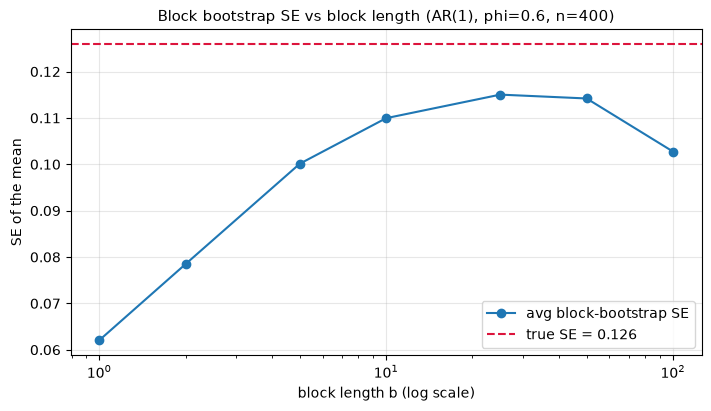

  b  avg SE
  1  0.0621
  2  0.0785
  5  0.1001
 10  0.1099
 25  0.1150
 50  0.1142
100  0.1027

b=1 is exactly the iid bootstrap (about half the true SE here). As b grows,
more serial dependence is preserved and the SE climbs toward the truth;
by b ~ 25-50 it is close. At b = 100 only 4 distinct blocks fit in n = 400,
so the SE estimate itself becomes noisy - the classic bias/variance
trade-off behind the b ~ n^(1/3) rule of thumb.


In [22]:
# --- Solution ---
b_grid = [1, 2, 5, 10, 25, 50, 100]
B_e3, n_series_e3 = 300, 100
avg_se = []
for b in b_grid:
    k = n_ts // b
    ses = np.empty(n_series_e3)
    for i in range(n_series_e3):
        x = series_all[i]
        starts = rng.integers(0, n_ts - b + 1, (B_e3, k))
        bidx = (starts[:, :, None] + np.arange(b)).reshape(B_e3, -1)
        ses[i] = x[bidx].mean(axis=1).std(ddof=1)
    avg_se.append(ses.mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(b_grid, avg_se, "o-", label="avg block-bootstrap SE")
ax.axhline(se_true_mc, color="crimson", ls="--", label=f"true SE = {se_true_mc:.3f}")
ax.set_xscale("log")
ax.set(title="Block bootstrap SE vs block length (AR(1), phi=0.6, n=400)",
       xlabel="block length b (log scale)", ylabel="SE of the mean")
ax.legend()
plt.show()

print(pd.DataFrame({"b": b_grid, "avg SE": np.round(avg_se, 4)}).to_string(index=False))
print("\nb=1 is exactly the iid bootstrap (about half the true SE here). As b grows,"
      "\nmore serial dependence is preserved and the SE climbs toward the truth;"
      "\nby b ~ 25-50 it is close. At b = 100 only 4 distinct blocks fit in n = 400,"
      "\nso the SE estimate itself becomes noisy - the classic bias/variance"
      "\ntrade-off behind the b ~ n^(1/3) rule of thumb.")